In [75]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.1


In [76]:
train = pd.read_csv("FNN and CNN/CIFAR10/cifar-10.csv")

print("Dataset shape:", train.shape)
train.head()

Dataset shape: (50000, 3073)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [77]:
x = train.drop("label", axis=1).values
y = train["label"].values

print("Features shape:", x.shape)
print("Labels shape:", y.shape)
print("Unique labels:", np.unique(y))

Features shape: (50000, 3072)
Labels shape: (50000,)
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [78]:
x = x.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1) / 255.0

print("Image shape:", x.shape)

Image shape: (50000, 32, 32, 3)


In [79]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [80]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [81]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step - accuracy: 0.4268 - loss: 1.5807 - val_accuracy: 0.5337 - val_loss: 1.3233
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.5665 - loss: 1.2352 - val_accuracy: 0.5835 - val_loss: 1.1956
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.6163 - loss: 1.0961 - val_accuracy: 0.6225 - val_loss: 1.0825
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.6505 - loss: 1.0063 - val_accuracy: 0.6403 - val_loss: 1.0452
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.6756 - loss: 0.9348 - val_accuracy: 0.6598 - val_loss: 0.9887
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.6970 - loss: 0.8786 - val_accuracy: 0.6709 - val_loss: 0.9602
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.7129 - loss: 0.8331 - val_accuracy: 0.6725 - val_loss: 0.9476
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - accuracy: 0.7282 - loss: 0.7881 - 

In [83]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6843 - loss: 0.9272
Test Loss: 0.927194356918335
Test Accuracy: 0.6843000054359436


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


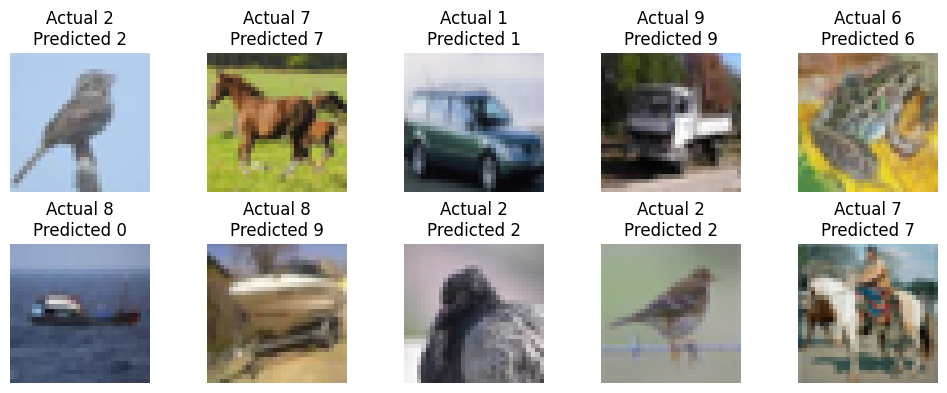

In [85]:
prediction = model.predict(x_test[:10])

predicted_digit = prediction.argmax(axis = 1)

plt.figure(figsize=(10 , 4))
for i in range(10):
    plt.subplot(2 , 5 , i+1)
    plt.imshow(x_test[i])
    plt.title(f"Actual {y_test[i]}\nPredicted {predicted_digit[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


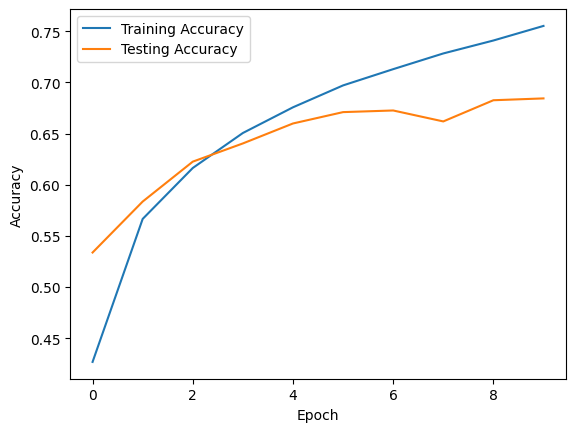

In [86]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Testing Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

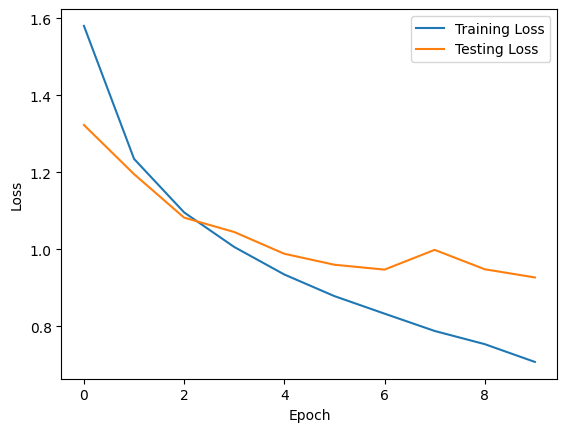

In [87]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [88]:
y_pred = model.predict(x_test)
y_pred = np.argmax(y_pred, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Confusion Matrix:
[[697  41  76  10  22  12   8  17  82  35]
 [ 22 813   6  15  10   8  10   6  32  78]
 [ 55  10 572  55 115  84  58  30  16   5]
 [ 19  10  80 454  70 214  90  30  14  19]
 [ 17   6  61  53 676  53  49  63  14   8]
 [ 10   8  77 153  58 593  32  59   8   2]
 [  2  11  58  54  53  27 782   7   6   0]
 [ 17   5  41  44  74  91  11 704   5   8]
 [ 59  31  26   8  12  10  11   5 815  23]
 [ 34  87  18  20  11  21  11  13  48 737]]

Classification Report:
              precision    recall  f1-score   support

    Airplane       0.75      0.70      0.72      1000
  Automobile       0.80      0.81      0.80      1000
        Bird       0.56      0.57      0.57      1000
         Cat       0.52      0.45      0.49      1000
        Deer       0.61      0.68      0.64      1000
         Dog       0.53      0.59      0.56      1000
        Frog       0.74      0.78      0.76      1000
       Horse       0.75      0.70      0.73      1000